In [ ]:
%pip install --upgrade --force-reinstall numpy==1.26.4 scikit-learn==1.6.1 pandas joblib

  Using cached numpy-1.26.4-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
  Using cached scikit_learn-1.6.1-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (18 kB)
  Using cached pandas-3.1.1-cp312-cp312-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (16 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)


In [17]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

# Create folders before saving anything
os.makedirs("model", exist_ok=True)
os.makedirs("results", exist_ok=True)

print("Libraries imported successfully!")
print("Project folders created!")

Libraries imported successfully!
Project folders created!


In [19]:
dataset = load_breast_cancer()

X = pd.DataFrame(
    dataset.data,
    columns=dataset.feature_names
)

# Target: 0 = Benign, 1 = Malignant
y = pd.Series(1 - dataset.target, name="target")

df = X.copy()
df["target"] = y

print("Dataset loaded successfully!")
print("Total records:", df.shape[0])
print("Total features:", X.shape[1])

print("\nClass Distribution:")
print(y.value_counts().rename(
    index={0: "Benign", 1: "Malignant"}
))

print("\nMissing values:", df.isnull().sum().sum())

display(df.head())

Dataset loaded successfully!
Total records: 569
Total features: 30

Class Distribution:
target
Benign       357
Malignant    212
Name: count, dtype: int64

Missing values: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data splitting completed!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("Training features:", X_train.shape[1])
print("Testing features:", X_test.shape[1])

Data splitting completed!
Training samples: 455
Testing samples: 114
Training features: 30
Testing features: 30


In [23]:
models = {

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=2000))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Naive Bayes": GaussianNB(),

    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        ))
    ])
}

print("Five classification models initialized successfully!")

for model_name in models:
    print("-", model_name)

Five classification models initialized successfully!
- Logistic Regression
- Decision Tree
- KNN
- Naive Bayes
- Support Vector Machine


In [25]:
results = []
trained_models = {}
predictions = {}

for name, model in models.items():

    print("\nTraining:", name)

    # Train model
    model.fit(X_train, y_train)

    # Predictions
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Evaluation metrics
    metrics = {
        "ML Model Name": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_prob),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    }

    results.append(metrics)

    trained_models[name] = model
    predictions[name] = y_pred

    # Save trained model
    filename = name.lower().replace(" ", "_") + ".joblib"

    joblib.dump(
        model,
        os.path.join("model", filename)
    )

    print(name, "trained and saved successfully!")

# Create comparison table
comparison_df = pd.DataFrame(results)

# Save comparison table
comparison_df.to_csv(
    "results/comparison.csv",
    index=False
)

print("\nFINAL MODEL COMPARISON")
display(comparison_df.round(4))


Training: Logistic Regression
Logistic Regression trained and saved successfully!

Training: Decision Tree
Decision Tree trained and saved successfully!

Training: KNN
KNN trained and saved successfully!

Training: Naive Bayes
Naive Bayes trained and saved successfully!

Training: Support Vector Machine
Support Vector Machine trained and saved successfully!

FINAL MODEL COMPARISON


,ML Model Name,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
1,Decision Tree,0.9211,0.9448,0.9459,0.8333,0.8861,0.8299
2,KNN,0.9561,0.9823,0.9744,0.9048,0.9383,0.9058
3,Naive Bayes,0.9386,0.9934,1.0000,0.8333,0.9091,0.8715
4,Support Vector Machine,0.9737,0.9947,1.0000,0.9286,0.9630,0.9442


In [27]:
best_model = comparison_df.sort_values(
    by="F1 Score",
    ascending=False
).iloc[0]

print("MODEL PERFORMANCE OBSERVATIONS\n")

for _, row in comparison_df.iterrows():

    print("Model:", row["ML Model Name"])
    print("Accuracy:", round(row["Accuracy"], 4))
    print("AUC:", round(row["AUC"], 4))
    print("F1 Score:", round(row["F1 Score"], 4))

    if row["F1 Score"] >= 0.95:
        print("Observation: Excellent classification performance.")
    elif row["F1 Score"] >= 0.90:
        print("Observation: Strong classification performance.")
    else:
        print("Observation: Comparatively lower performance.")

    print("-" * 50)

print("\nOVERALL WINNER:", best_model["ML Model Name"])
print("Winning F1 Score:", round(best_model["F1 Score"], 4))

MODEL PERFORMANCE OBSERVATIONS

Model: Logistic Regression
Accuracy: 0.9649
AUC: 0.996
F1 Score: 0.9512
Observation: Excellent classification performance.
--------------------------------------------------
Model: Decision Tree
Accuracy: 0.9211
AUC: 0.9448
F1 Score: 0.8861
Observation: Comparatively lower performance.
--------------------------------------------------
Model: KNN
Accuracy: 0.9561
AUC: 0.9823
F1 Score: 0.9383
Observation: Strong classification performance.
--------------------------------------------------
Model: Naive Bayes
Accuracy: 0.9386
AUC: 0.9934
F1 Score: 0.9091
Observation: Strong classification performance.
--------------------------------------------------
Model: Support Vector Machine
Accuracy: 0.9737
AUC: 0.9947
F1 Score: 0.963
Observation: Excellent classification performance.
--------------------------------------------------

OVERALL WINNER: Support Vector Machine
Winning F1 Score: 0.963


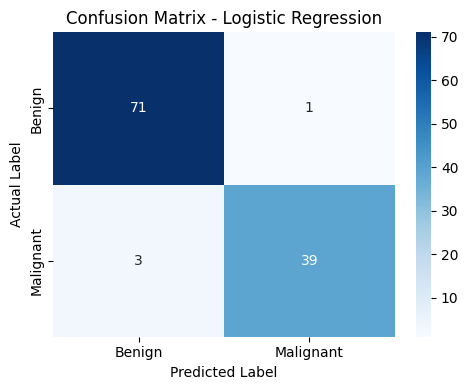


Classification Report: Logistic Regression
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



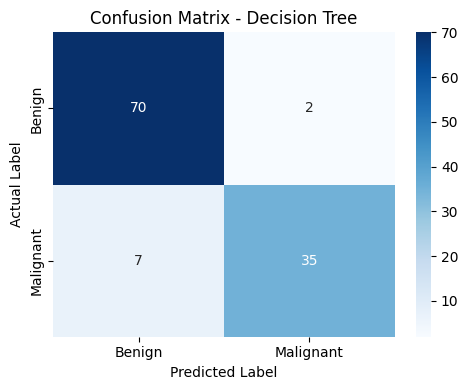


Classification Report: Decision Tree
              precision    recall  f1-score   support

      Benign       0.91      0.97      0.94        72
   Malignant       0.95      0.83      0.89        42

    accuracy                           0.92       114
   macro avg       0.93      0.90      0.91       114
weighted avg       0.92      0.92      0.92       114



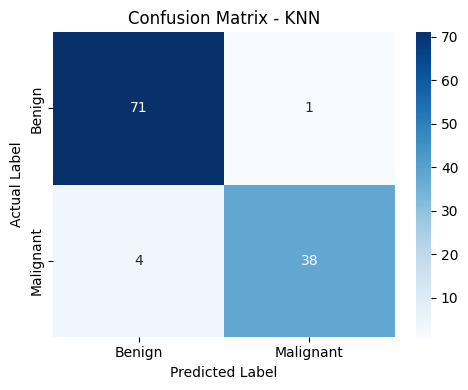


Classification Report: KNN
              precision    recall  f1-score   support

      Benign       0.95      0.99      0.97        72
   Malignant       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



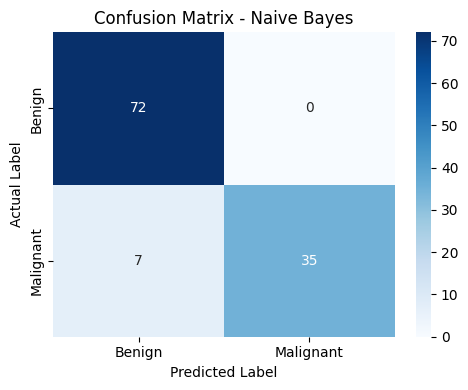


Classification Report: Naive Bayes
              precision    recall  f1-score   support

      Benign       0.91      1.00      0.95        72
   Malignant       1.00      0.83      0.91        42

    accuracy                           0.94       114
   macro avg       0.96      0.92      0.93       114
weighted avg       0.94      0.94      0.94       114



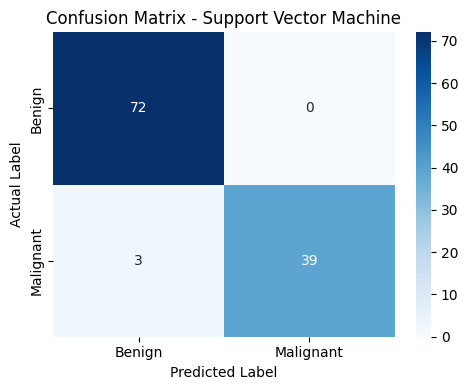


Classification Report: Support Vector Machine
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



In [29]:
for name, y_pred in predictions.items():

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Benign", "Malignant"],
        yticklabels=["Benign", "Malignant"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.show()

    print("\nClassification Report:", name)
    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["Benign", "Malignant"],
            zero_division=0
        )
    )

In [31]:
test_data = X_test.copy()

test_data["target"] = y_test

test_data.to_csv(
    "test_data.csv",
    index=False
)

print("Test dataset exported successfully!")
print("Test data shape:", test_data.shape)

display(test_data.head())

print("\nFile saved as test_data.csv")

Test dataset exported successfully!
Test data shape: (114, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
120,11.41,10.82,73.34,403.3,0.09373,0.06685,0.03512,0.02623,0.1667,0.06113,...,15.97,83.74,510.5,0.1548,0.2390,0.21020,0.08958,0.3016,0.08523,0
250,20.94,23.56,138.90,1364.0,0.10070,0.16060,0.27120,0.13100,0.2205,0.05898,...,27.00,165.30,2010.0,0.1211,0.3172,0.69910,0.21050,0.3126,0.07849,1
375,16.17,16.07,106.30,788.5,0.09880,0.14380,0.06651,0.05397,0.1990,0.06572,...,19.14,113.10,861.5,0.1235,0.2550,0.21140,0.12510,0.3153,0.08960,0
99,14.42,19.77,94.48,642.5,0.09752,0.11410,0.09388,0.05839,0.1879,0.06390,...,30.86,109.50,826.4,0.1431,0.3026,0.31940,0.15650,0.2718,0.09353,1
455,13.38,30.72,86.34,557.2,0.09245,0.07426,0.02819,0.03264,0.1375,0.06016,...,41.61,96.69,705.6,0.1172,0.1421,0.07003,0.07763,0.2196,0.07675,0



File saved as test_data.csv


In [33]:
print("SAVED MODEL FILES")

for file in os.listdir("model"):
    print("✓", file)

print("\nRESULT FILES")

for file in os.listdir("results"):
    print("✓", file)

print("\nTEST DATA")
print("✓ test_data.csv")

print("\nFINAL MODEL METRICS")
display(comparison_df.round(4))

print("\nASSIGNMENT MODEL IMPLEMENTATION COMPLETED!")

SAVED MODEL FILES
✓ logistic_regression.joblib
✓ decision_tree.joblib
✓ knn.joblib
✓ naive_bayes.joblib
✓ support_vector_machine.joblib

RESULT FILES
✓ comparison.csv

TEST DATA
✓ test_data.csv

FINAL MODEL METRICS


,ML Model Name,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
1,Decision Tree,0.9211,0.9448,0.9459,0.8333,0.8861,0.8299
2,KNN,0.9561,0.9823,0.9744,0.9048,0.9383,0.9058
3,Naive Bayes,0.9386,0.9934,1.0000,0.8333,0.9091,0.8715
4,Support Vector Machine,0.9737,0.9947,1.0000,0.9286,0.9630,0.9442



ASSIGNMENT MODEL IMPLEMENTATION COMPLETED!


In [35]:
%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import joblib
import os

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

st.set_page_config(
    page_title="Breast Cancer Classification",
    page_icon="🧬",
    layout="wide"
)

st.title("🧬 Breast Cancer Classification Dashboard")
st.write(
    "An interactive comparison of five machine learning "
    "classification algorithms."
)

st.sidebar.header("Model Configuration")

model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "support_vector_machine.joblib"
}

selected_model = st.sidebar.selectbox(
    "Select Classification Model",
    list(model_files.keys())
)

st.subheader("Upload Test Dataset")

uploaded_file = st.file_uploader(
    "Upload your test CSV file",
    type=["csv"]
)

if uploaded_file is not None:

    data = pd.read_csv(uploaded_file)

    st.write("Uploaded Dataset Preview")
    st.dataframe(data.head())

    if "target" not in data.columns:
        st.error("CSV must contain the target column.")
        st.stop()

    X = data.drop(columns=["target"])
    y = data["target"]

    if y.isna().any() or not set(y.unique()).issubset({0, 1}):
        st.error("Target must contain only 0 and 1 without missing values.")
        st.stop()

    expected_features = 30

    if X.shape[1] != expected_features:
        st.error("Dataset must contain exactly 30 input features.")
        st.stop()

    model_path = os.path.join(
        "model",
        model_files[selected_model]
    )

    if not os.path.exists(model_path):
        st.error("Selected trained model file was not found.")
        st.stop()

    model = joblib.load(model_path)

    try:
        y_pred = model.predict(X)
        y_prob = model.predict_proba(X)[:, 1]

        accuracy = accuracy_score(y, y_pred)
        auc = roc_auc_score(y, y_prob)
        precision = precision_score(y, y_pred, zero_division=0)
        recall = recall_score(y, y_pred, zero_division=0)
        f1 = f1_score(y, y_pred, zero_division=0)
        mcc = matthews_corrcoef(y, y_pred)

        st.success(f"{selected_model} evaluated successfully!")

        st.subheader("Evaluation Metrics")

        c1, c2, c3 = st.columns(3)
        c4, c5, c6 = st.columns(3)

        c1.metric("Accuracy", f"{accuracy:.4f}")
        c2.metric("AUC Score", f"{auc:.4f}")
        c3.metric("Precision", f"{precision:.4f}")
        c4.metric("Recall", f"{recall:.4f}")
        c5.metric("F1 Score", f"{f1:.4f}")
        c6.metric("MCC Score", f"{mcc:.4f}")

        st.subheader("Confusion Matrix")

        cm = confusion_matrix(y, y_pred, labels=[0, 1])

        st.dataframe(
            pd.DataFrame(
                cm,
                index=["Actual Benign", "Actual Malignant"],
                columns=["Predicted Benign", "Predicted Malignant"]
            )
        )

        st.subheader("Classification Report")

        report = classification_report(
            y,
            y_pred,
            target_names=["Benign", "Malignant"],
            output_dict=True,
            zero_division=0
        )

        st.dataframe(pd.DataFrame(report).transpose())

    except Exception as error:
        st.error(f"Evaluation failed: {error}")

else:
    st.info("Upload test_data.csv to evaluate your selected model.")

st.divider()
st.caption("M.Tech AIML | Machine Learning Assignment 2 | BITS Pilani")

Writing app.py


In [37]:
%%writefile requirements.txt

streamlit
numpy==1.26.4
pandas==2.2.3
scikit-learn==1.6.1
joblib
matplotlib
seaborn

Writing requirements.txt


In [39]:
%%writefile README.md

# Breast Cancer Classification Using Machine Learning

## 1. Problem Statement

The objective of this project is to develop and compare five machine learning classification algorithms to classify breast cancer cases as Benign or Malignant.

The project also provides an interactive Streamlit application for evaluating trained models using uploaded test data.

## 2. Dataset Description

Dataset: Breast Cancer Wisconsin (Diagnostic)

Source: UCI Machine Learning Repository

Source URL:
https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic

- Total Instances: 569
- Total Features: 30
- Target Classes: 2
- Benign: 357
- Malignant: 212
- Training Records: 455
- Testing Records: 114
- Train-Test Split: 80:20

Target encoding:
- 0 = Benign
- 1 = Malignant

## 3. GitHub Repository Link

REPLACE_WITH_YOUR_GITHUB_REPOSITORY_URL

## 4. Machine Learning Models and Evaluation

Five classification algorithms were implemented:

1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbors
4. Gaussian Naive Bayes
5. Support Vector Machine

### Evaluation Metrics

| ML Model Name | Accuracy | AUC | Precision | Recall | F1 Score | MCC |
|---|---:|---:|---:|---:|---:|---:|
| Logistic Regression | 0.9649 | 0.9960 | 0.9750 | 0.9286 | 0.9512 | 0.9245 |
| Decision Tree | 0.9211 | 0.9448 | 0.9459 | 0.8333 | 0.8861 | 0.8299 |
| KNN | 0.9561 | 0.9823 | 0.9744 | 0.9048 | 0.9383 | 0.9058 |
| Naive Bayes | 0.9386 | 0.9934 | 1.0000 | 0.8333 | 0.9091 | 0.8715 |
| Support Vector Machine | 0.9737 | 0.9947 | 1.0000 | 0.9286 | 0.9630 | 0.9442 |

### Model Performance Observations

| Model | Observation |
|---|---|
| Logistic Regression | Achieved 96.49% accuracy and excellent AUC of 0.9960. |
| Decision Tree | Achieved 92.11% accuracy with comparatively lower recall. |
| KNN | Delivered strong performance with 95.61% accuracy. |
| Naive Bayes | Achieved perfect precision but comparatively lower recall. |
| Support Vector Machine | Achieved the highest accuracy, F1 score and MCC among the five models. |

### Overall Winner

Support Vector Machine (SVM) is the best-performing model on the selected test dataset.

- Accuracy: 97.37%
- AUC: 0.9947
- Precision: 1.0000
- Recall: 0.9286
- F1 Score: 0.9630
- MCC: 0.9442

## 5. Streamlit Application

The Streamlit application provides:

- CSV test dataset upload.
- Classification model selection.
- Evaluation metric display.
- Confusion matrix.
- Classification report.
- Model comparison.

The application loads previously trained models without retraining on uploaded test data.

Live Application:
REPLACE_WITH_YOUR_STREAMLIT_APP_URL

## 6. Project Structure

```text
ML_Classification_Assignment_2/
|
|-- app.py
|-- requirements.txt
|-- README.md
|-- test_data.csv
|-- ML_Classification_Models.ipynb
|
|-- model/
|   |-- logistic_regression.joblib
|   |-- decision_tree.joblib
|   |-- knn.joblib
|   |-- naive_bayes.joblib
|   |-- support_vector_machine.joblib
|
|-- results/
    |-- comparison.csv

Writing README.md


In [41]:
import os

print("========== PROJECT FILE CHECK ==========")

files = [
    "app.py",
    "requirements.txt",
    "README.md",
    "test_data.csv",
    "ML_Classification_Models.ipynb",
    "model/logistic_regression.joblib",
    "model/decision_tree.joblib",
    "model/knn.joblib",
    "model/naive_bayes.joblib",
    "model/support_vector_machine.joblib",
    "results/comparison.csv"
]

for file in files:
    status = "PASS" if os.path.exists(file) else "MISSING"
    print(f"{status}: {file}")

print("\n========== VERIFICATION COMPLETED ==========")

========== PROJECT FILE CHECK ==========
PASS: app.py
PASS: requirements.txt
PASS: README.md
PASS: test_data.csv
PASS: ML_Classification_Models.ipynb
PASS: model/logistic_regression.joblib
PASS: model/decision_tree.joblib
PASS: model/knn.joblib
PASS: model/naive_bayes.joblib
PASS: model/support_vector_machine.joblib
PASS: results/comparison.csv

========== VERIFICATION COMPLETED ==========


In [ ]:
import zipfile
import os

project_files = [
    "app.py",
    "requirements.txt",
    "README.md",
    "test_data.csv",
    "ML_Classification_Models.ipynb",
    "model/logistic_regression.joblib",
    "model/decision_tree.joblib",
    "model/knn.joblib",
    "model/naive_bayes.joblib",
    "model/support_vector_machine.joblib",
    "results/comparison.csv"
]

with zipfile.ZipFile(
    "ML_Classification_Assignment_2.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for file in project_files:
        if os.path.exists(file):
            zip_file.write(file)

print("Clean project ZIP created!")
print("Size:", round(
    os.path.getsize("ML_Classification_Assignment_2.zip") / 1024,
    2
), "KB")